In [1]:
# ==== Cohort Binder (DO NOT MODIFY) ==== 
import hashlib, json, random, numpy as np, datetime, os 
import matplotlib.pyplot as plt 
STUDENT_NAME = input("Enter your full name: ").strip() 
ROLL_NO      = input("Enter your college roll number: ").strip() 
SALT         = "AIML_Capstone_2026"   # fixed by instructor 
sig_str = json.dumps({"n": STUDENT_NAME, "r": ROLL_NO, "s": SALT}) 
STUDENT_SIG = hashlib.sha256(sig_str.encode()).hexdigest()[:12] 
SEED = int(STUDENT_SIG[:8], 16) % (2**31-1) 
random.seed(SEED) 
np.random.seed(SEED) 
TODAY = datetime.date.today().isoformat() 
OUT_PREFIX = f"AIML_{STUDENT_SIG}_{TODAY}" 
os.makedirs("out", exist_ok=True) 
def stamp_plot(title): 
    plt.title(f"{title}\nSIG:{STUDENT_SIG} DATE:{TODAY}") 
print(f"Student: {STUDENT_NAME} | College Roll No: {ROLL_NO}") 
print(f"Signature: {STUDENT_SIG} | Seed: {SEED}") 
print(f"Output prefix: out/{OUT_PREFIX}_*") 

Student: GADAMSETTY NAGA MANIKANTA THARUN | College Roll No: 24UCS123
Signature: c5c95b70276e | Seed: 1170824049
Output prefix: out/AIML_c5c95b70276e_2026-07-14_*


In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#import required libraries and data 
bank_data=pd.read_csv("Dataset File/bank.csv")
bank_data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [4]:
bank_data.shape

(11162, 17)

In [5]:
bank_data.isna().sum()
#There are no null values in the dataset

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [6]:
bank_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [7]:
#to find any insignificant types in any categorical columns we should seperate them and find them using value counts
categorical_columns = bank_data.select_dtypes(include="object").columns
print(categorical_columns)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='str')


C:\Users\gmani\AppData\Local\Temp\ipykernel_24864\1485540100.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = bank_data.select_dtypes(include="object").columns


In [8]:
for col in categorical_columns:
    print(f"{col}:")
    print(bank_data[col].value_counts())
    print("-" * 40)

job:
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64
----------------------------------------
marital:
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64
----------------------------------------
education:
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64
----------------------------------------
default:
default
no     10994
yes      168
Name: count, dtype: int64
----------------------------------------
housing:
housing
no     5881
yes    5281
Name: count, dtype: int64
----------------------------------------
loan:
loan
no     9702
yes    1460
Name: count, dtype: int64
----------------------------------------
contact:
contact
cellular     8042
unknown   

In [9]:
#there are unknown values in job,education,contact,poutcome these should not be removed because some of the other quantities may be significant
#the data is balanced as we can see in deposit
bank_data.duplicated().sum()

np.int64(0)

In [10]:
#There are no duplicate rows
bank_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


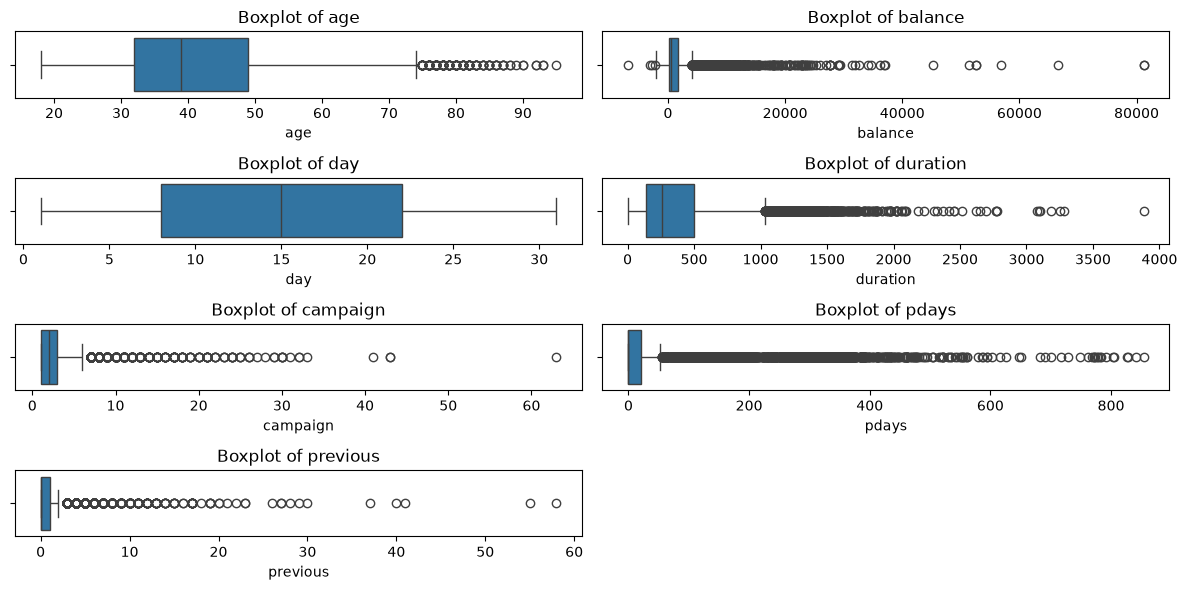

In [11]:
#Now let us visualise the graphs of numerical values on boxplots so tthat we can get a idea of outliers
numerical_cols = bank_data.select_dtypes(include=['int64', 'float64']).columns
fig,axes = plt.subplots(4, 2, figsize=(12, 6))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.boxplot(x=bank_data[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xlabel(col)
axes[7].set_visible(False)
plt.tight_layout()
plt.show()

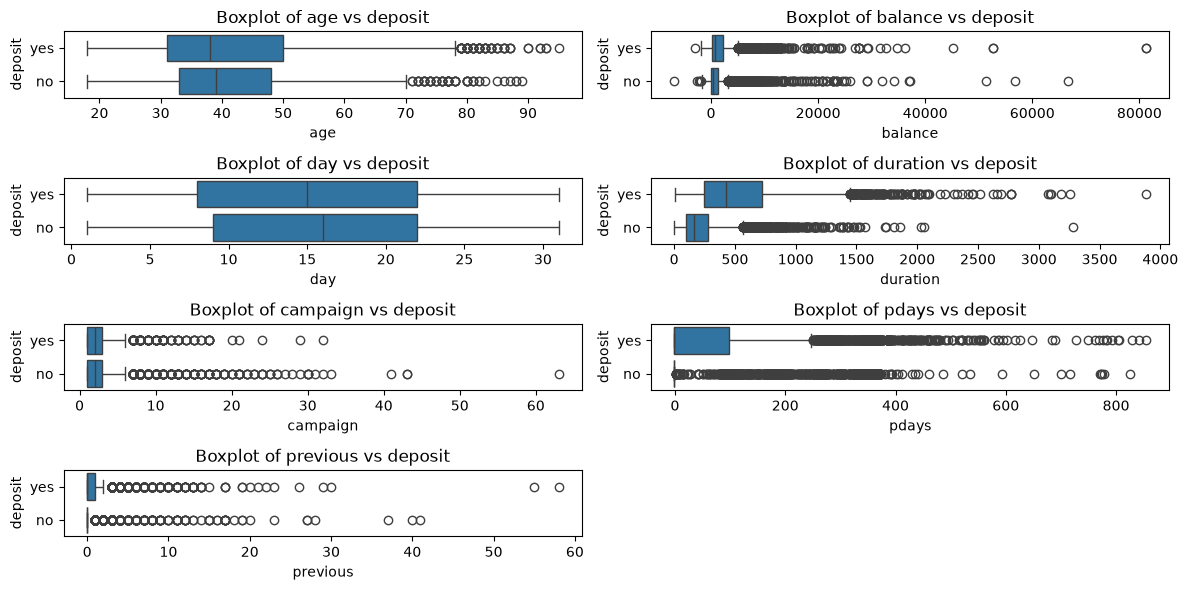

In [12]:
#as there are many outliers as this is bank data if we remove outliers we may lose our valuable customers who pay deposit such as balance case
numerical_cols = bank_data.select_dtypes(include=['int64', 'float64']).columns
fig,axes=plt.subplots(4, 2, figsize=(12, 6))
axes=axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.boxplot(x=bank_data[col],y=bank_data["deposit"], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col} vs deposit')
    axes[i].set_xlabel(col)
axes[7].set_visible(False)
plt.tight_layout()
plt.show()

C:\Users\gmani\AppData\Local\Temp\ipykernel_24864\2846175400.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = bank_data.select_dtypes(include="object").columns


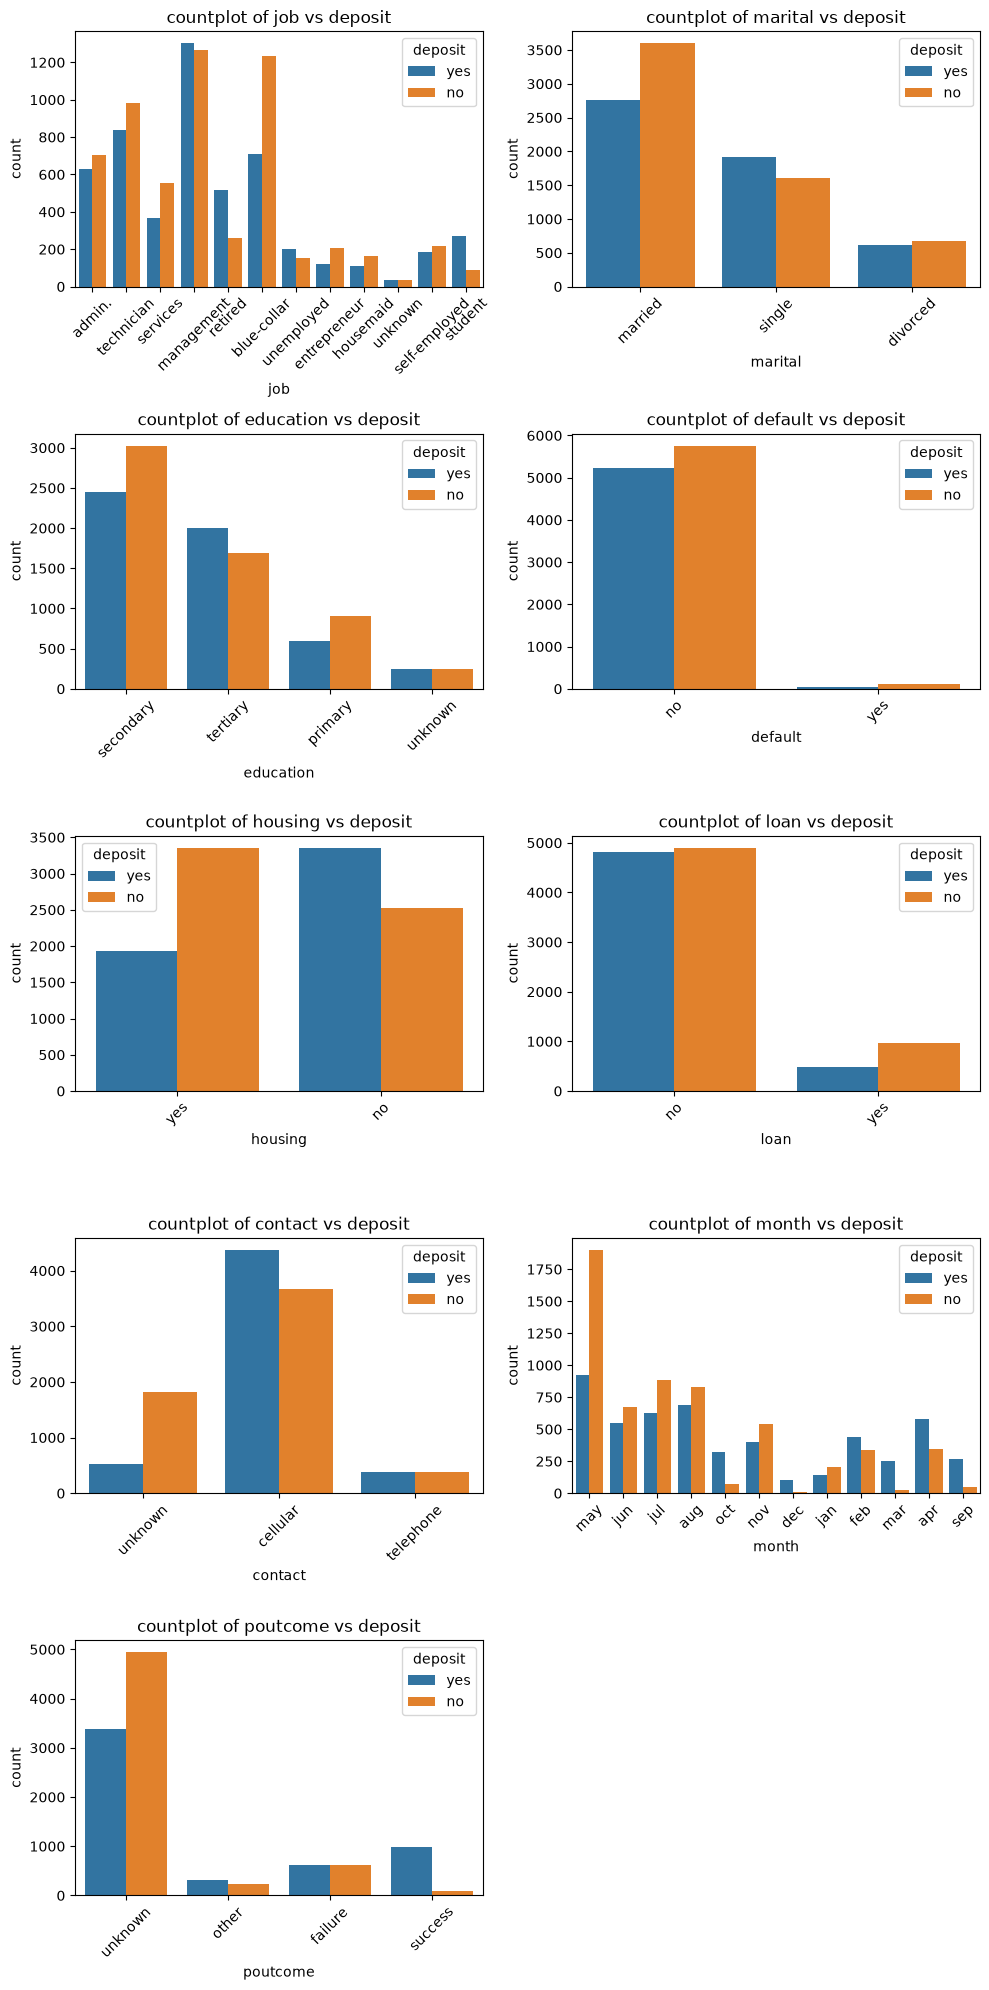

In [13]:
categorical_cols = bank_data.select_dtypes(include="object").columns
categorical_cols = categorical_cols.drop("deposit")
fig, axes = plt.subplots(5, 2, figsize=(10, 20))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(x=bank_data[col], ax=axes[i],hue=bank_data["deposit"])
    axes[i].set_title(f'countplot of {col} vs deposit')
    axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation=45)
axes[9].set_visible(False)
plt.tight_layout()
plt.show()

In [14]:
#from count plot of fig 1 we can infer that our top three job holders who keep deposit are management ,technician and bluecollar
#from fig 2 we can infer that married people prefer not to keep money as deposit than single and divorced people
#in fig 3 we can infer that as the education level of people is increased the people who tend to keep deposit in bank are mostly educated ones who had financial knowledge
#we can also see that as the education level became tertiary the most educated people are preferring other investing sources other than deposit
#from fig 4 we can say that the people with default previously are very less almost nill to pay for term deposit
#from fig 5 we can say that the people without house loan are mostly the people who deposit money
#from fig 6 we can say that people with loan are less likely to deposit 
#from gig 7 we can say the people whom we had contacted via cellular connection are more likely to pay term deposit
#from fig 8 may is the peak season where the people had payed term deposit and december is the worst month for campaign
#from fig 9 we can say the unknown kind of cases paid the most deposit
binary_cols = ['default', 'housing', 'loan', 'deposit']

for col in binary_cols:
    bank_data[col] = bank_data[col].map({'yes': 1, 'no': 0})

In [15]:
categorical_cols = [
    'job',
    'marital',
    'education',
    'contact',
    'month',
    'poutcome'
]

bank_data = pd.get_dummies(
    bank_data,
    columns=categorical_cols,
    dtype=int
)
#in the above step before sending any data to machine learning model we need to encode them so we made the categorical values as numbers using one hot encoding

In [16]:
bank_data.head(10)

,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,59,0,2343,1,0,5,1042,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
1,56,0,45,0,0,5,1467,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
2,41,0,1270,1,0,5,1389,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
3,55,0,2476,1,0,5,579,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
4,54,0,184,0,0,5,673,2,-1,0,...,0,0,1,0,0,0,0,0,0,1
5,42,0,0,1,1,5,562,2,-1,0,...,0,0,1,0,0,0,0,0,0,1
6,56,0,830,1,1,6,1201,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
7,60,0,545,1,0,6,1030,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
8,37,0,1,1,0,6,608,1,-1,0,...,0,0,1,0,0,0,0,0,0,1
9,28,0,5090,1,0,6,1297,3,-1,0,...,0,0,1,0,0,0,0,0,0,1


In [17]:
bank_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 49 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   age                  11162 non-null  int64
 1   default              11162 non-null  int64
 2   balance              11162 non-null  int64
 3   housing              11162 non-null  int64
 4   loan                 11162 non-null  int64
 5   day                  11162 non-null  int64
 6   duration             11162 non-null  int64
 7   campaign             11162 non-null  int64
 8   pdays                11162 non-null  int64
 9   previous             11162 non-null  int64
 10  deposit              11162 non-null  int64
 11  job_admin.           11162 non-null  int64
 12  job_blue-collar      11162 non-null  int64
 13  job_entrepreneur     11162 non-null  int64
 14  job_housemaid        11162 non-null  int64
 15  job_management       11162 non-null  int64
 16  job_retired          11162 non-nu

In [18]:
#Now seperate the target column
X=bank_data.drop(columns={"deposit"})
y=bank_data["deposit"]

In [19]:
#spli the data
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1170824049,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(8929, 48)
(2233, 48)


In [21]:
#standaradizing the data for logistic regression model ,for decision tree we do not need to standardize but in this step even if we standardize it doesnt't matter 
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [22]:
#training the model
from sklearn.linear_model import LogisticRegression

lr=LogisticRegression(random_state=1170824049,max_iter=1000)#kept randomstate as seed 

lr.fit(X_train_scaled,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",1170824049
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [23]:
#predicting the values
y_pred_lr=lr.predict(X_test_scaled)

In [24]:
#seeing the performance of logistic regression model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print(classification_report(y_test, y_pred_lr))

print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.8092252575011196
              precision    recall  f1-score   support

           0       0.80      0.85      0.82      1175
           1       0.82      0.77      0.79      1058

    accuracy                           0.81      2233
   macro avg       0.81      0.81      0.81      2233
weighted avg       0.81      0.81      0.81      2233

[[996 179]
 [247 811]]


In [25]:
#importing decision tree model
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=2+((1170824049)%5),#modified according to seed 
    random_state=42
)

dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

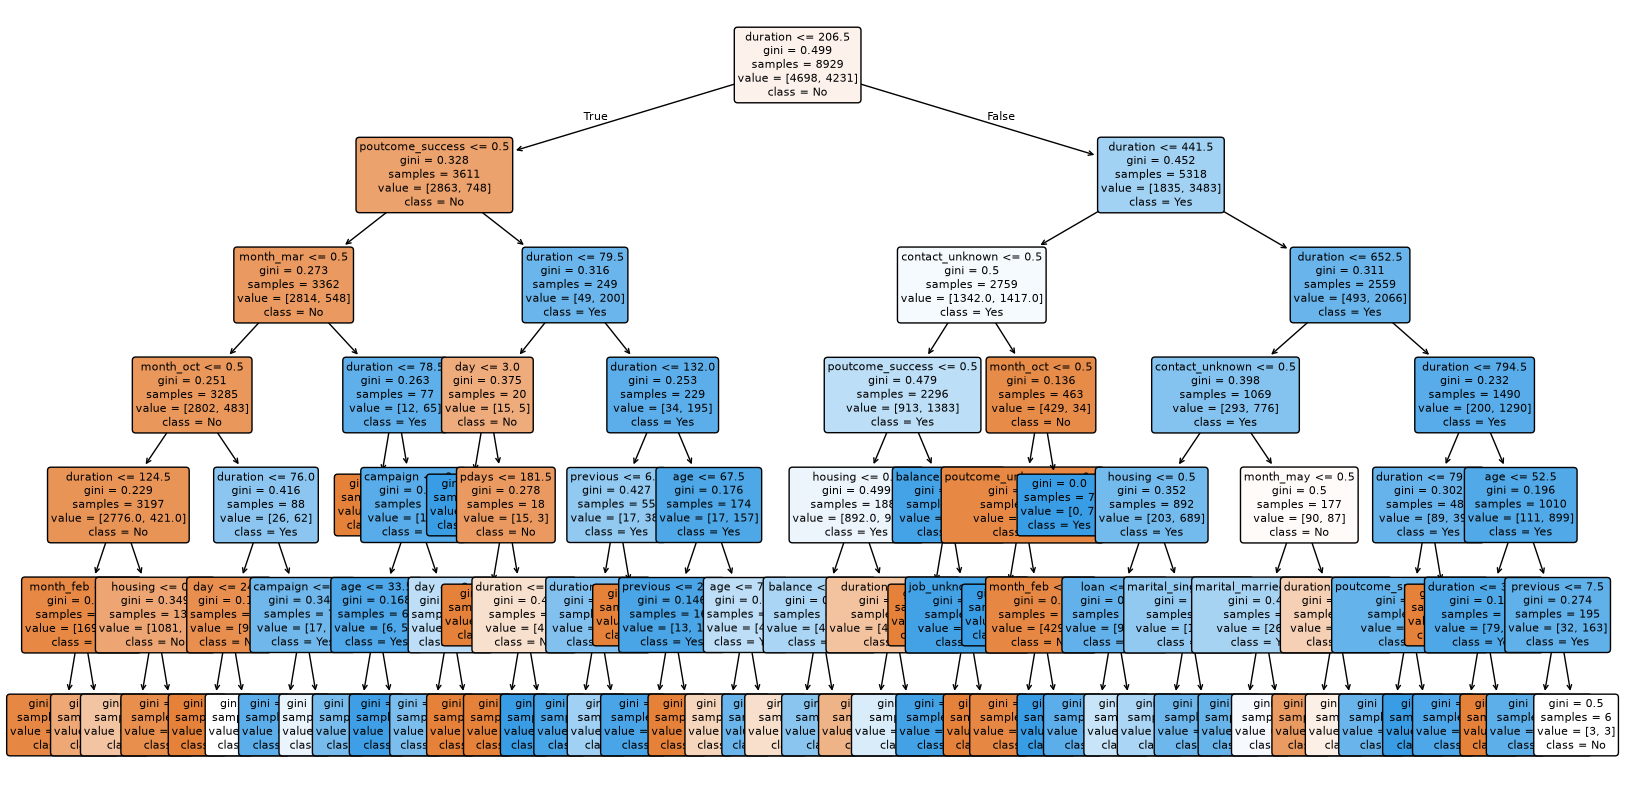

In [26]:
#plotting the decision tree diagram
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=['No','Yes'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

In [27]:
#predicting the data
y_pred_dt = dt.predict(X_test)

In [28]:
#seeing the performance of the modal with decision tree model
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))
print(confusion_matrix(y_test, y_pred_dt))

Accuracy: 0.799820868786386
              precision    recall  f1-score   support

           0       0.80      0.82      0.81      1175
           1       0.79      0.78      0.79      1058

    accuracy                           0.80      2233
   macro avg       0.80      0.80      0.80      2233
weighted avg       0.80      0.80      0.80      2233

[[962 213]
 [234 824]]


In [29]:
#checking the results
results=pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred_dt
})
results.head()

,Actual,Predicted
8016,0,1
6262,0,0
9394,0,0
1490,1,0
10705,0,0


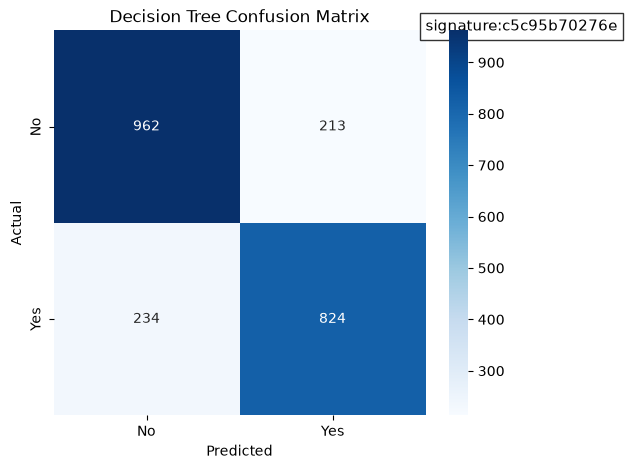

In [30]:
#the confusion matrix plot saved with signature for decision tree 
cm = confusion_matrix(y_test, y_pred_dt)

fig, ax = plt.subplots(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No','Yes'],
    yticklabels=['No','Yes'],
    ax=ax
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Decision Tree Confusion Matrix")

ax.text(
    1, 1,                      # Position (relative to axes)
    "signature:c5c95b70276e", # Multi-line text
    transform=ax.transAxes,
    fontsize=11,
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.show()

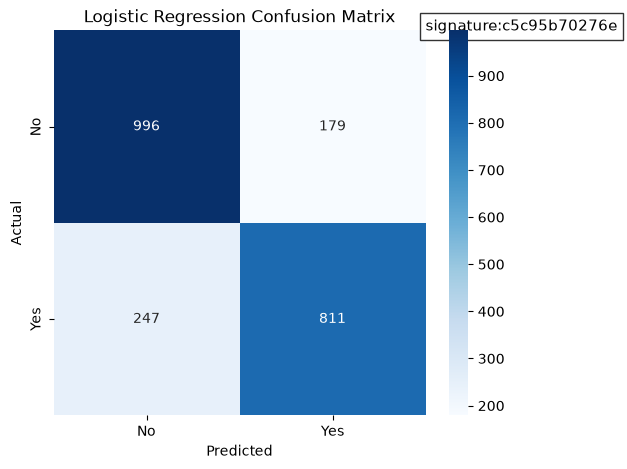

In [31]:
#confusion matrix plot for logistic regression model
cm = confusion_matrix(y_test, y_pred_lr)

fig, ax = plt.subplots(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No','Yes'],
    yticklabels=['No','Yes'],
    ax=ax
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Logistic Regression Confusion Matrix")

ax.text(
    1, 1,                      # Position (relative to axes)
    "signature:c5c95b70276e", # Multi-line text
    transform=ax.transAxes,
    fontsize=11,
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.show()

In [32]:
#Final conclusion based on Accuracy,Precision,Recall,F1-Score and confusion matrix
#by observing the above data based on accuracy_score we can say logistic regression model outperformed decision tree model in every metric so we can conclude logistic 
#regression model is better than decision tree model.